In [1]:
!pip install pillow
!pip install open3d-python

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Python314\python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Python314\python.exe -m pip install --upgrade pip


In [2]:

from pathlib import Path
from PIL import Image
import numpy as np


# # BASE_DIR = Path(__file__).resolve().parent
# DATA= BASE_DIR / "rgbd_dataset_freiburg1_room"

DATA= Path("rgbd_dataset_freiburg1_room")


def read_file(filename):
    rows = []
    with open(DATA / filename) as file:
        for line in file:
            if line.startswith("#") or not line.strip():
                continue
            values = line.split()
            rows.append((float(values[0]), values[1:]))
    return rows


def closest(rows, timestamp):
    return min(rows, key=lambda row: abs(row[0] - timestamp))


rgb_list = read_file("rgb.txt")
depth_list = read_file("depth.txt")
pose_list = read_file("groundtruth.txt")

# Select the first RGB frame
rgb_time, rgb_info = rgb_list[0]

# Find nearest depth and camera pose
depth_time, depth_info = closest(depth_list, rgb_time)
pose_time, pose_info = closest(pose_list, rgb_time)

# Check timestamp differences
assert abs(rgb_time - depth_time) < 0.05
assert abs(rgb_time - pose_time) < 0.05

# Load images
rgb = np.array(Image.open(DATA / rgb_info[0]).convert("RGB"))
depth = np.array(Image.open(DATA / depth_info[0]))

# TUM depth: 5000 units = 1 meter
depth = depth.astype(np.float32) / 5000.0

# Camera pose: tx, ty, tz, qx, qy, qz, qw
pose = np.array(pose_info, dtype=float)

print("RGB shape:", rgb.shape)
print("Depth shape:", depth.shape)
print("Camera position:", pose[:3])
print("Camera quaternion:", pose[3:])

valid = depth[depth > 0]
print("Valid depth pixels:", valid.size)
print("Minimum depth (m):", valid.min())
print("Maximum depth (m):", valid.max())


RGB shape: (480, 640, 3)
Depth shape: (480, 640)
Camera position: [-0.8683  0.6026  1.5627]
Camera quaternion: [ 0.8219 -0.3912  0.1615 -0.3811]
Valid depth pixels: 220546
Minimum depth (m): 0.7972
Maximum depth (m): 2.9826


3D points shape: (220546, 3)
Colors shape: (220546, 3)


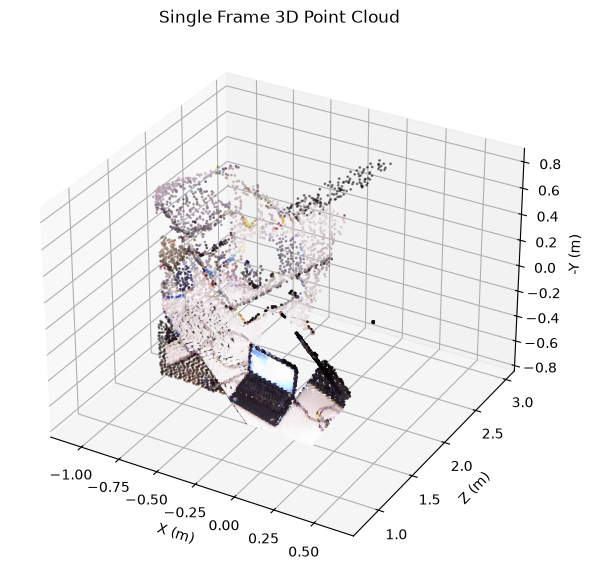

In [3]:

import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

# ROOT = Path(__file__).resolve().parent
# if str(ROOT) not in sys.path:
#     sys.path.insert(0, str(ROOT))

# Assuming rgb and depth have been loaded
# from our previous load_data.py
# from load_data import rgb, depth

# TUM Freiburg 1 intrinsics
fx = 525.0
fy = 525.0
cx = 319.5
cy = 239.5

height, width = depth.shape

# Create pixel coordinates
u, v = np.meshgrid(
    np.arange(width),
    np.arange(height)
)

# Keep only valid depth pixels
valid = depth > 0

z = depth[valid]
x = (u[valid] - cx) * z / fx
y = (v[valid] - cy) * z / fy

# Combine into 3D points
points = np.column_stack((x, y, z))

# Get corresponding RGB colors
colors = rgb[valid] / 255.0

print("3D points shape:", points.shape)
print("Colors shape:", colors.shape)

# Preview points in 3D
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

# Plot a subset for faster visualization
step = 20

ax.scatter(
    points[::step, 0],
    points[::step, 2],
    -points[::step, 1],
    c=colors[::step],
    s=1
)

ax.set_xlabel("X (m)")
ax.set_ylabel("Z (m)")
ax.set_zlabel("-Y (m)")
ax.set_title("Single Frame 3D Point Cloud")

plt.show()


Processed frame 0
Processed frame 151
Processed frame 302
Processed frame 453
Processed frame 604
Processed frame 756
Processed frame 907
Processed frame 1058
Processed frame 1209
Processed frame 1361
Total points before filtering: 2288300
Points after downsampling: 179206
Saved point cloud to: merged_room.ply
Saved point-cloud preview to: merged_room_preview.png


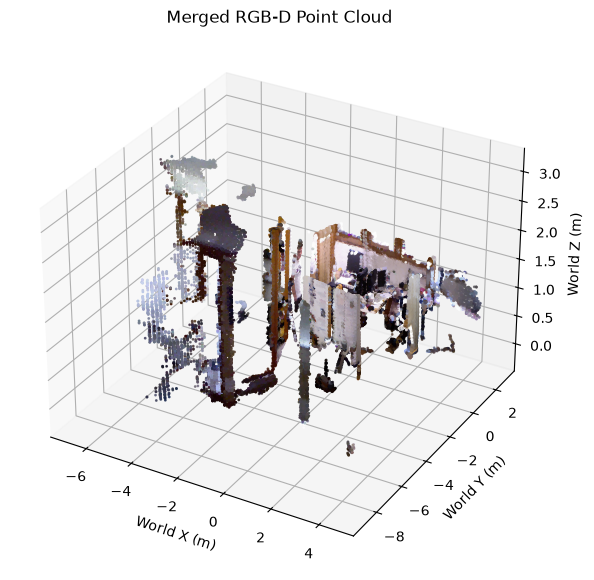

In [5]:

from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy.spatial.transform import Rotation

# BASE_DIR = Path(__file__).resolve().parent
# DATA = BASE_DIR / "rgbd_dataset_freiburg1_room"

# TUM Freiburg 1 intrinsics
fx, fy = 525.0, 525.0
cx, cy = 319.5, 239.5


def read_file(filename):
    rows = []

    with open(DATA / filename) as file:
        for line in file:
            if line.startswith("#") or not line.strip():
                continue

            values = line.split()
            rows.append((float(values[0]), values[1:]))

    return rows


def closest(rows, timestamp):
    return min(rows, key=lambda row: abs(row[0] - timestamp))


def voxel_downsample(points, colors, voxel_size):
    voxel_ids = np.floor(points / voxel_size).astype(np.int64)
    _, inverse = np.unique(voxel_ids, axis=0, return_inverse=True)
    voxel_counts = np.bincount(inverse)

    downsampled_points = np.column_stack(
        [
            np.bincount(inverse, weights=points[:, axis]) / voxel_counts
            for axis in range(3)
        ]
    )
    downsampled_colors = np.column_stack(
        [
            np.bincount(inverse, weights=colors[:, channel]) / voxel_counts
            for channel in range(3)
        ]
    )
    return downsampled_points, downsampled_colors


def save_colored_ply(filename, points, colors):
    rgb = np.clip(np.round(colors * 255), 0, 255).astype(np.uint8)
    with filename.open("w", encoding="ascii") as ply_file:
        ply_file.write(
            "ply\n"
            "format ascii 1.0\n"
            f"element vertex {len(points)}\n"
            "property float x\n"
            "property float y\n"
            "property float z\n"
            "property uchar red\n"
            "property uchar green\n"
            "property uchar blue\n"
            "end_header\n"
        )
        np.savetxt(
            ply_file,
            np.column_stack((points, rgb)),
            fmt=["%.6f", "%.6f", "%.6f", "%d", "%d", "%d"],
        )


if not DATA.is_dir():
    raise FileNotFoundError(f"Dataset directory not found: {DATA}")


rgb_list = read_file("rgb.txt")
depth_list = read_file("depth.txt")
pose_list = read_file("groundtruth.txt")

if not rgb_list or not depth_list or not pose_list:
    raise ValueError("RGB, depth, or ground-truth timestamp list is empty.")

all_points = []
all_colors = []

# Select 10 frames spread across the recording
indices = np.linspace(
    0, len(rgb_list) - 1, 10, dtype=int
)

for index in indices:
    rgb_time, rgb_info = rgb_list[index]
    depth_time, depth_info = closest(depth_list, rgb_time)
    pose_time, pose_info = closest(pose_list, rgb_time)

    # Skip frames that are not synchronized
    if abs(rgb_time - depth_time) > 0.05:
        continue

    if abs(rgb_time - pose_time) > 0.05:
        continue

    rgb = np.array(
        Image.open(DATA / rgb_info[0]).convert("RGB")
    )

    depth = np.array(
        Image.open(DATA / depth_info[0]),
        dtype=np.float32
    ) / 5000.0

    height, width = depth.shape
    if rgb.shape[:2] != depth.shape:
        raise ValueError(
            f"RGB/depth dimensions differ for frame {index}: "
            f"{rgb.shape[:2]} vs {depth.shape}"
        )

    u, v = np.meshgrid(
        np.arange(width),
        np.arange(height)
    )

    valid = depth > 0

    z = depth[valid]
    x = (u[valid] - cx) * z / fx
    y = (v[valid] - cy) * z / fy

    points = np.column_stack((x, y, z))
    colors = rgb[valid] / 255.0

    # Camera-to-world transformation
    pose = np.array(pose_info, dtype=float)
    translation = pose[:3]
    quaternion = pose[3:]

    R = Rotation.from_quat(quaternion).as_matrix()

    points_world = points @ R.T + translation

    all_points.append(points_world)
    all_colors.append(colors)

    print(f"Processed frame {index}")

# Combine all frames
if not all_points:
    raise ValueError(
        "No frames were processed: none met the 50 ms synchronization threshold."
    )

merged_points = np.vstack(all_points)
merged_colors = np.vstack(all_colors)

print("Total points before filtering:", len(merged_points))

# Reduce overlapping points
merged_points, merged_colors = voxel_downsample(
    merged_points, merged_colors, voxel_size=0.02
)

print("Points after downsampling:", len(merged_points))

# Save beside this script so the output location does not depend on the
# directory from which the script was launched.
output_path = Path("merged_room.ply")
save_colored_ply(output_path, merged_points, merged_colors)
print(f"Saved point cloud to: {output_path}")

# Display a subset to keep rendering responsive.
display_step = max(1, len(merged_points) // 50_000)
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(
    merged_points[::display_step, 0],
    merged_points[::display_step, 1],
    merged_points[::display_step, 2],
    c=merged_colors[::display_step],
    s=1,
)
ax.set_xlabel("World X (m)")
ax.set_ylabel("World Y (m)")
ax.set_zlabel("World Z (m)")
ax.set_title("Merged RGB-D Point Cloud")
preview_path = Path("merged_room_preview.png")
fig.savefig(preview_path, dpi=150, bbox_inches="tight")
print(f"Saved point-cloud preview to: {preview_path}")
plt.show()


In [7]:

import open3d as o3d

# Load merged point cloud
pcd = o3d.io.read_point_cloud("merged_room.ply")

print("Total points:", len(pcd.points))

# Detect largest plane using RANSAC
plane_model, inliers = pcd.segment_plane(
    distance_threshold=0.02,
    ransac_n=3,
    num_iterations=1000
)

a, b, c, d = plane_model

print(f"Plane equation: {a:.4f}x + {b:.4f}y + {c:.4f}z + {d:.4f} = 0")
print("Plane points:", len(inliers))
print("Remaining points:", len(pcd.points) - len(inliers))

# Separate plane and remaining points
plane_cloud = pcd.select_by_index(inliers)
remaining_cloud = pcd.select_by_index(inliers, invert=True)

# Highlight detected plane in red
plane_cloud.paint_uniform_color([1, 0, 0])

# Save detected plane
o3d.io.write_point_cloud("detected_plane.ply", plane_cloud)

# Visualize
o3d.visualization.draw_geometries(
    [plane_cloud, remaining_cloud],
    window_name="RANSAC Plane Detection",
    width=1200,
    height=800
)


Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.
Total points: 179206
Plane equation: -0.0259x + -0.0229y + 0.9994z + -0.7408 = 0
Plane points: 16332
Remaining points: 162874


In [2]:

import open3d as o3d

pcd = o3d.io.read_point_cloud("merged_room.ply")

remaining = pcd
colors = [
    [1, 0, 0],
    [0, 1, 0],
    [0, 0, 1],
    [1, 1, 0],
    [1, 0, 1]
]

detected_planes = []

for i in range(5):

    if len(remaining.points) < 1000:
        break

    model, inliers = remaining.segment_plane(
        distance_threshold=0.02,
        ransac_n=3,
        num_iterations=1000
    )

    if len(inliers) < 1000:
        break

    plane = remaining.select_by_index(inliers)
    plane.paint_uniform_color(colors[i])

    detected_planes.append(plane)

    print(f"\nPlane {i + 1}")
    print("Equation:", model)
    print("Points:", len(inliers))

    remaining = remaining.select_by_index(
        inliers, invert=True
    )

# Visualize all detected planes
o3d.visualization.draw_geometries(
    detected_planes + [remaining],
    window_name="Multiple Plane Detection",
    width=1200,
    height=800
)



Plane 1
Equation: [-0.02003796 -0.01845845  0.99962881 -0.73441881]
Points: 15990

Plane 2
Equation: [ 0.05618151  0.99448981 -0.08850789 -2.28279083]
Points: 10308

Plane 3
Equation: [-0.05423066  0.01222477  0.9984536  -0.77593452]
Points: 8915

Plane 4
Equation: [-0.00377156 -0.02646285  0.99964268 -0.79910573]
Points: 7709

Plane 5
Equation: [ 1.47307330e-02 -6.97236541e-04  9.99891254e-01 -2.17408730e-03]
Points: 7405


In [ ]:
import os
import numpy as np
import open3d as o3d

print("open3d version:", o3d.__version__)

root = "rgbd_dataset_freiburg1_room"
STEP = 3
DEPTH_TRUNC = 4.0

def read_list(fname):
    out = []
    for l in open(os.path.join(root, fname)):
        if l.startswith("#") or not l.strip():
            continue
        p = l.split()
        out.append((float(p[0]), p[1:]))
    return out

def nearest(ts, t):
    i = int(np.argmin(np.abs(ts - t)))
    return i, abs(ts[i] - t)

def gt_to_mat(v):
    tx, ty, tz, qx, qy, qz, qw = map(float, v)
    q = np.array([qw, qx, qy, qz]); q /= np.linalg.norm(q)
    T = np.eye(4)
    T[:3, :3] = o3d.geometry.get_rotation_matrix_from_quaternion(q)
    T[:3, 3] = [tx, ty, tz]
    return T  # camera -> world

rgb_list, depth_list, gt_list = read_list("rgb.txt"), read_list("depth.txt"), read_list("groundtruth.txt")
d_ts = np.array([t for t, _ in depth_list])
g_ts = np.array([t for t, _ in gt_list])

frames = []
for t, rp in rgb_list:
    di, dd = nearest(d_ts, t)
    gi, gd = nearest(g_ts, t)
    if dd < 0.02 and gd < 0.05:
        frames.append((rp[0], depth_list[di][1][0], gt_to_mat(gt_list[gi][1])))
frames = frames[::STEP]
print("frames:", len(frames))

intr = o3d.camera.PinholeCameraIntrinsic(640, 480, 517.3, 516.5, 318.6, 255.3)
gt0_inv = np.linalg.inv(frames[0][2])

def load(rp, dp):
    c = o3d.io.read_image(os.path.join(root, rp))
    d = o3d.io.read_image(os.path.join(root, dp))
    return o3d.geometry.RGBDImage.create_from_color_and_depth(
        c, d, depth_scale=5000.0, depth_trunc=DEPTH_TRUNC, convert_rgb_to_intensity=False)

# ---------- 1) point-cloud fusion (no TSDF) ----------
fused = o3d.geometry.PointCloud()
for k, (rp, dp, T) in enumerate(frames):
    c2w = gt0_inv @ T
    pcd = o3d.geometry.PointCloud.create_from_rgbd_image(load(rp, dp), intr, np.linalg.inv(c2w))
    fused += pcd.voxel_down_sample(0.01)
    if k % 20 == 0:
        fused = fused.voxel_down_sample(0.01)
        print(f"pcd frame {k}/{len(frames)}  points: {len(fused.points)}")
fused = fused.voxel_down_sample(0.01)
print("fused points:", len(fused.points))
o3d.io.write_point_cloud("room_fused.ply", fused)

# ---------- 2) TSDF with several configs ----------
def run_tsdf(color_type, label):
    vol = o3d.pipelines.integration.ScalableTSDFVolume(
        voxel_length=0.01, sdf_trunc=0.04, color_type=color_type)
    for rp, dp, T in frames:
        c2w = gt0_inv @ T
        vol.integrate(load(rp, dp), intr, np.linalg.inv(c2w))
    m = vol.extract_triangle_mesh()
    print(f"TSDF [{label}] vertices: {len(m.vertices)}")
    return m

mesh = None
for ct, name in [(o3d.pipelines.integration.TSDFVolumeColorType.NoColor, "NoColor"),
                 (o3d.pipelines.integration.TSDFVolumeColorType.RGB8, "RGB8")]:
    m = run_tsdf(ct, name)
    if len(m.vertices) > 0:
        mesh = m
        break

axes = o3d.geometry.TriangleMesh.create_coordinate_frame(size=0.3)
if mesh is not None:
    mesh.compute_vertex_normals()
    o3d.io.write_triangle_mesh("room_mesh.ply", mesh)
    o3d.visualization.draw_geometries([mesh, axes])
else:
    print("TSDF still empty -> showing fused point cloud instead")
    o3d.visualization.draw_geometries([fused, axes])

open3d version: 0.20.0
frames: 454
pcd frame 0/454  points: 27899
pcd frame 20/454  points: 258819
pcd frame 40/454  points: 378190
pcd frame 60/454  points: 616548
pcd frame 80/454  points: 1171312
pcd frame 100/454  points: 1500675
pcd frame 120/454  points: 1843762
pcd frame 140/454  points: 1831904
pcd frame 160/454  points: 2022733
pcd frame 180/454  points: 2294092
pcd frame 200/454  points: 2576553
pcd frame 220/454  points: 2678291
pcd frame 240/454  points: 2782558
pcd frame 260/454  points: 3208418
pcd frame 280/454  points: 3562038
pcd frame 300/454  points: 3867275
pcd frame 320/454  points: 4130495
pcd frame 340/454  points: 4201291
pcd frame 360/454  points: 4298965
pcd frame 380/454  points: 4374326
pcd frame 400/454  points: 4543535
pcd frame 420/454  points: 4616314
pcd frame 440/454  points: 4724054
fused points: 4749375
TSDF [NoColor] vertices: 0
TSDF [RGB8] vertices: 0
TSDF still empty -> showing fused point cloud instead


: 

In [1]:
import os
import numpy as np
import open3d as o3d
import open3d.core as o3c

print("open3d:", o3d.__version__)

root = "rgbd_dataset_freiburg1_room"
STEP = 2
VOXEL = 0.01
DEPTH_TRUNC = 3.5
MAX_JUMP = 0.25          # meters between consecutive frames, reject odometry above this

def read_list(fname):
    out = []
    for l in open(os.path.join(root, fname)):
        if l.startswith("#") or not l.strip():
            continue
        p = l.split()
        out.append((float(p[0]), p[1:]))
    return out

def nearest(ts, t):
    i = int(np.argmin(np.abs(ts - t)))
    return i, abs(ts[i] - t)

rgb_list, depth_list = read_list("rgb.txt"), read_list("depth.txt")
d_ts = np.array([t for t, _ in depth_list])

frames = []   # (timestamp, rgb_path, depth_path)  -- NO poses
for t, rp in rgb_list:
    di, dd = nearest(d_ts, t)
    if dd < 0.02:
        frames.append((t, rp[0], depth_list[di][1][0]))
frames = frames[::STEP]
print("frames:", len(frames))

W, H, FX, FY, CX, CY = 640, 480, 525.0, 525.0, 319.5, 229.5
intr = o3d.camera.PinholeCameraIntrinsic(W, H, FX, FY, CX, CY)

def load(rp, dp, gray):
    c = o3d.io.read_image(os.path.join(root, rp))
    d = o3d.io.read_image(os.path.join(root, dp))
    return o3d.geometry.RGBDImage.create_from_color_and_depth(
        c, d, depth_scale=5000.0, depth_trunc=DEPTH_TRUNC, convert_rgb_to_intensity=gray)

# ---------------- 1) pose estimation: RGB-D odometry only ----------------
opt = o3d.pipelines.odometry.OdometryOption()
jac = o3d.pipelines.odometry.RGBDOdometryJacobianFromHybridTerm()

poses = [np.eye(4)]            # camera -> world, first frame = origin
prev = load(frames[0][1], frames[0][2], True)
last_rel = np.eye(4)
fails = 0
for k in range(1, len(frames)):
    cur = load(frames[k][1], frames[k][2], True)
    ok, rel, _ = o3d.pipelines.odometry.compute_rgbd_odometry(
        cur, prev, intr, last_rel, jac, opt)     # rel: cur cam -> prev cam
    if ok and np.linalg.norm(rel[:3, 3]) < MAX_JUMP:
        last_rel = rel
    else:
        fails += 1
        rel = last_rel                           # constant-velocity fallback
    poses.append(poses[-1] @ rel)
    prev = cur
    if k % 50 == 0:
        print(f"odometry {k}/{len(frames)}  fails: {fails}")
print("odometry fails total:", fails)

# ---------------- 2) always-works check: fused point cloud ----------------
fused = o3d.geometry.PointCloud()
for k, (t, rp, dp) in enumerate(frames):
    p = o3d.geometry.PointCloud.create_from_rgbd_image(
        load(rp, dp, False), intr, np.linalg.inv(poses[k]))
    fused += p.voxel_down_sample(VOXEL * 2)
    if k % 25 == 0:
        fused = fused.voxel_down_sample(VOXEL * 2)
fused = fused.voxel_down_sample(VOXEL * 2)
print("fused points:", len(fused.points))
o3d.io.write_point_cloud("room_fused.ply", fused)

# ---------------- 3) TSDF mesh (legacy first, tensor VoxelBlockGrid fallback) ----------------
def tsdf_legacy():
    vol = o3d.pipelines.integration.ScalableTSDFVolume(
        voxel_length=VOXEL, sdf_trunc=VOXEL * 4,
        color_type=o3d.pipelines.integration.TSDFVolumeColorType.RGB8)
    for k, (t, rp, dp) in enumerate(frames):
        vol.integrate(load(rp, dp, False), intr, np.linalg.inv(poses[k]))
    return vol.extract_triangle_mesh()

def tsdf_tensor():
    dev = o3c.Device("CPU:0")
    vbg = o3d.t.geometry.VoxelBlockGrid(
        attr_names=("tsdf", "weight", "color"),
        attr_dtypes=(o3c.float32, o3c.float32, o3c.float32),
        attr_channels=((1), (1), (3)),
        voxel_size=VOXEL, block_resolution=16, block_count=100000, device=dev)
    K = o3c.Tensor(intr.intrinsic_matrix, o3c.float64)
    for k, (t, rp, dp) in enumerate(frames):
        depth = o3d.t.io.read_image(os.path.join(root, dp)).to(dev)
        color = o3d.t.io.read_image(os.path.join(root, rp)).to(dev)
        ext = o3c.Tensor(np.linalg.inv(poses[k]), o3c.float64)
        coords = vbg.compute_unique_block_coordinates(depth, K, ext, 5000.0, DEPTH_TRUNC)
        vbg.integrate(coords, depth, color, K, ext, 5000.0, DEPTH_TRUNC)
    return vbg.extract_triangle_mesh().to_legacy()

mesh = tsdf_legacy()
print("legacy TSDF vertices:", len(mesh.vertices))
if len(mesh.vertices) == 0:
    mesh = tsdf_tensor()
    print("tensor TSDF vertices:", len(mesh.vertices))

axes = o3d.geometry.TriangleMesh.create_coordinate_frame(size=0.3)
if len(mesh.vertices) > 0:
    mesh.compute_vertex_normals()
    o3d.io.write_triangle_mesh("room_mesh.ply", mesh)
    o3d.visualization.draw_geometries([mesh, axes])
else:
    print("Both TSDF paths empty -> showing point cloud")
    o3d.visualization.draw_geometries([fused, axes])

# ---------------- 4) EVALUATION ONLY: compare trajectory to TUM ground truth ----------------
gt_list = read_list("groundtruth.txt")
g_ts = np.array([t for t, _ in gt_list])
est, gt = [], []
for k, (t, _, _) in enumerate(frames):
    gi, gd = nearest(g_ts, t)
    if gd < 0.05:
        est.append(poses[k][:3, 3])
        gt.append(np.array(gt_list[gi][1][:3], float))
est, gt = np.array(est), np.array(gt)

# rigid alignment (Umeyama, no scale) since est starts at its own origin
mu_e, mu_g = est.mean(0), gt.mean(0)
U, _, Vt = np.linalg.svd((gt - mu_g).T @ (est - mu_e))
S = np.diag([1, 1, np.sign(np.linalg.det(U @ Vt))])
R = U @ S @ Vt
aligned = (R @ (est - mu_e).T).T + mu_g
ate = np.sqrt(np.mean(np.sum((aligned - gt) ** 2, axis=1)))
print(f"ATE RMSE vs ground truth: {ate*100:.1f} cm  (fr1/room is ~5-15 cm for odometry only, drift is expected)")

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.
open3d: 0.20.0
frames: 681
odometry 50/681  fails: 0
odometry 100/681  fails: 0
odometry 150/681  fails: 0
odometry 200/681  fails: 0
odometry 250/681  fails: 0
odometry 300/681  fails: 0
odometry 350/681  fails: 0
odometry 400/681  fails: 0
odometry 450/681  fails: 0
odometry 500/681  fails: 0
odometry 550/681  fails: 0
odometry 600/681  fails: 0
odometry 650/681  fails: 0
odometry fails total: 0
fused points: 921483
legacy TSDF vertices: 0
tensor TSDF vertices: 2005741
[Open3D WARNING] [ViewControl] SetViewPoint() failed because window height and width are not set.
ATE RMSE vs ground truth: 21.2 cm  (fr1/room is ~5-15 cm for odometry only, drift is expected)
